# Healthcare Analytics for Doctor Visits



## 1. Setup & Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import warnings

warnings.filterwarnings('ignore')

%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

GENDER_PALETTE = {'female': '#C2185B', 'male': '#1565C0'}
INS_ORDER = ['Private', 'None', 'Govt (low income)', 'Govt (old/disabled/veteran)']
INS_PALETTE = {'Private': '#2E7D32', 'None': '#757575', 'Govt (low income)': '#F9A825', 'Govt (old/disabled/veteran)': '#C62828'}
AGE_ORDER = ['<20', '20-29', '30-44', '45-59', '60+']

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Dataset Loaded Successfully

In [40]:
import pandas as pd
# Update this path if running locally
df = pd.read_csv('/content/1776250375-P2-Healthcare Analytics for Doctor Visits.csv')
print("Dataset loaded successfully.")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")

Dataset loaded successfully.
Shape: 5190 rows x 13 columns


## 3. Top 5 Rows Analyzed

In [4]:
df.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


## 4. Dataset Shape and Structure Examined

In [5]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print("\nColumn list:")
for i, c in enumerate(df.columns, 1):
    print(f"{i:2d}. {c}")

Rows: 5190
Columns: 13

Column list:
 1. Unnamed: 0
 2. visits
 3. gender
 4. age
 5. income
 6. illness
 7. reduced
 8. health
 9. private
10. freepoor
11. freerepat
12. nchronic
13. lchronic


In [6]:
categorical_cols = ['gender', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
for c in categorical_cols:
    print(f"--- {c}: {df[c].nunique()} unique values ---")
    print(df[c].value_counts())
    print()

--- gender: 2 unique values ---
gender
female    2702
male      2488
Name: count, dtype: int64

--- private: 2 unique values ---
private
no     2892
yes    2298
Name: count, dtype: int64

--- freepoor: 2 unique values ---
freepoor
no     4968
yes     222
Name: count, dtype: int64

--- freerepat: 2 unique values ---
freerepat
no     4099
yes    1091
Name: count, dtype: int64

--- nchronic: 2 unique values ---
nchronic
no     3098
yes    2092
Name: count, dtype: int64

--- lchronic: 2 unique values ---
lchronic
no     4585
yes     605
Name: count, dtype: int64



**Structure summary:** The dataset has 5,190 records across 13 columns: 1 row-index column, the target `visits`, 6 categorical/binary fields (`gender` plus 5 yes/no flags) and 5 numeric predictors (`age`, `income`, `illness`, `reduced`, `health`). The gender split is balanced (52% female / 48% male). Private insurance covers 44% of people, government cover for old age / disability / veterans 21%, and government cover for low income only 4%, so the low-income group is small and its estimates will be less stable.

## 5. Data Types Examined

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [8]:
dtype_summary = df.dtypes.value_counts()
print("Data type breakdown:")
print(dtype_summary)

Data type breakdown:
object     6
int64      5
float64    2
Name: count, dtype: int64


## 6. Missing Values Identified and Handled

In [9]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing)
print(f"\nTotal missing cells: {missing.sum()} ({missing.sum() / df.size * 100:.3f}% of all cells)")

Missing values per column:
Unnamed: 0    0
visits        0
gender        0
age           0
income        0
illness       0
reduced       0
health        0
private       0
freepoor      0
freerepat     0
nchronic      0
lchronic      0
dtype: int64

Total missing cells: 0 (0.000% of all cells)


## 7. Duplicate Records Identified and Handled

In [10]:
raw_index = df['Unnamed: 0']
print(f"Duplicate row-index values: {raw_index.duplicated().sum()}")
full_dupes = df.drop(columns='Unnamed: 0').duplicated().sum()
print(f"Rows identical to another row on every survey field (ignoring the index): {full_dupes} ({full_dupes/len(df):.1%})")

# Why these are NOT true duplicates: age and income take only a limited set of values
print(f"\nDistinct age values: {df['age'].nunique()}  |  Distinct income values: {df['income'].nunique()}")

survey = df.drop(columns='Unnamed: 0')
matching = survey.duplicated(keep=False)
print(f"Share with zero visits among matching rows: {(survey[matching]['visits']==0).mean():.1%}  |  among all rows: {(survey['visits']==0).mean():.1%}")

Duplicate row-index values: 0
Rows identical to another row on every survey field (ignoring the index): 1320 (25.4%)

Distinct age values: 12  |  Distinct income values: 14
Share with zero visits among matching rows: 94.8%  |  among all rows: 79.8%


## 8. Outliers Investigated

In [11]:
d = df.drop(columns='Unnamed: 0').copy()
d['age_years'] = (d['age'] * 100).round().astype(int)

outlier_cols = ['visits', 'age_years', 'income', 'illness', 'reduced', 'health']
outlier_report = []
for c in outlier_cols:
    q1, q3 = d[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((d[c] < lo) | (d[c] > hi)).sum()
    outlier_report.append({'Column': c, 'Lower_Bound': round(lo, 2), 'Upper_Bound': round(hi, 2),
                           'Outlier_Count': n_out, 'Outlier_pct': round(n_out / len(d) * 100, 2),
                           'Skew': round(d[c].skew(), 2)})
outlier_df = pd.DataFrame(outlier_report)
outlier_df

,Column,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_pct,Skew
0,visits,0.00,0.00,1049,20.21,4.74
1,age_years,-38.00,122.00,0,0.00,0.42
2,income,-0.73,1.88,0,0.00,0.73
3,illness,-3.00,5.00,0,0.00,0.94
4,reduced,0.00,0.00,736,14.18,3.83
5,health,-3.00,5.00,303,5.84,2.40


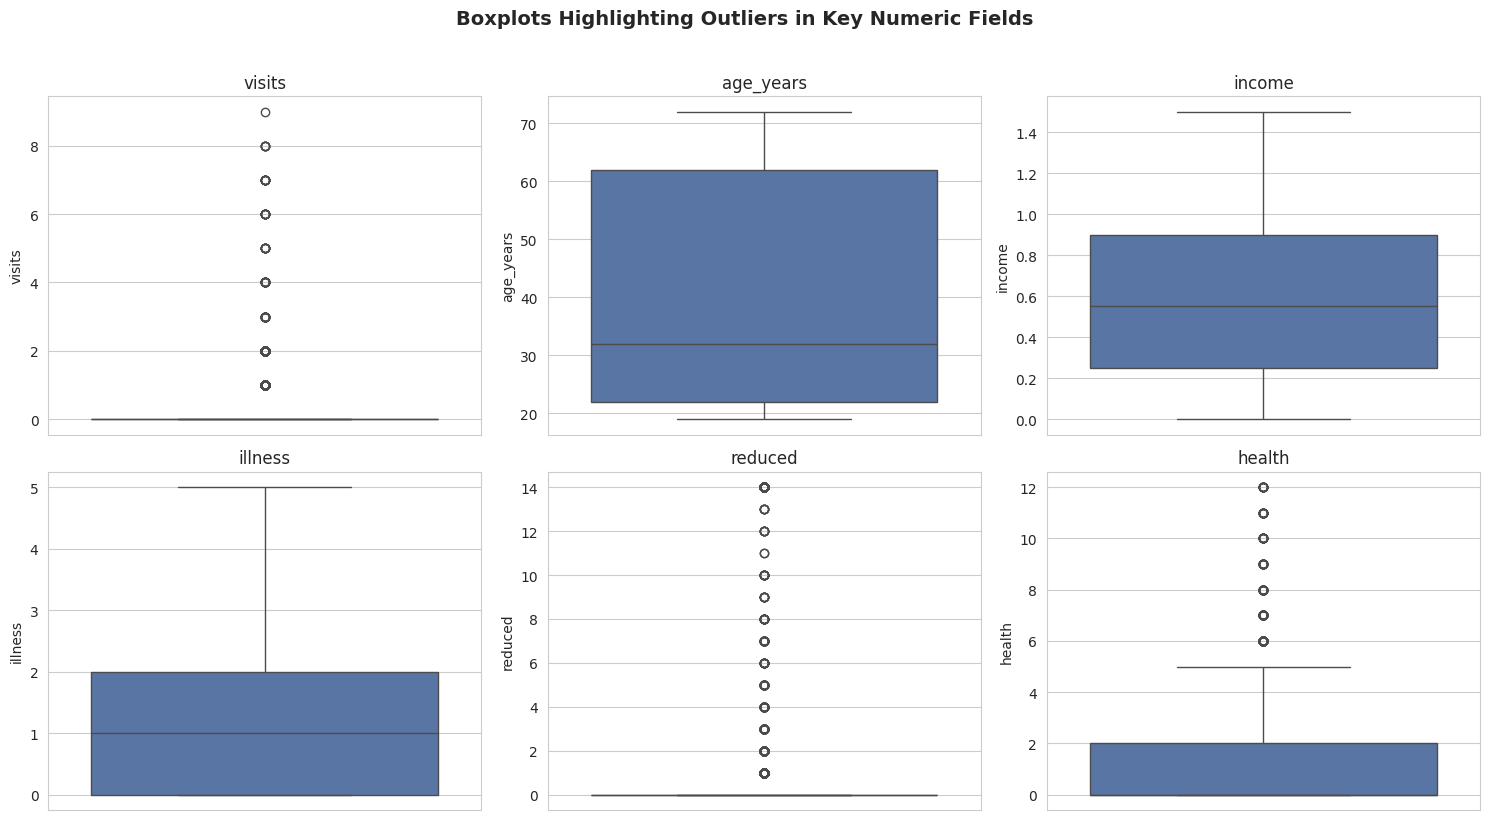

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flatten(), outlier_cols):
    sns.boxplot(y=d[c], ax=ax, color='#4C72B0')
    ax.set_title(c)
fig.suptitle('Boxplots Highlighting Outliers in Key Numeric Fields', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [13]:
# Investigate the heaviest users directly
print("Highest visit counts:")
display(d.nlargest(8, 'visits')[['visits', 'gender', 'age_years', 'illness', 'reduced', 'health', 'lchronic']])

print("\nAverage health profile: people with 3+ visits vs people with 0 visits")
d['heavy_user'] = d['visits'] >= 3
d.groupby('heavy_user')[['illness', 'reduced', 'health']].mean().round(2)

Highest visit counts:


,visits,gender,age_years,illness,reduced,health,lchronic
662,9,male,62,5,14,10,yes
47,8,female,19,2,7,0,yes
524,8,male,52,5,14,7,yes
598,8,male,57,1,9,4,no
629,8,female,62,1,14,1,no
742,8,male,67,2,14,5,no
114,7,male,22,1,14,1,no
333,7,female,27,1,3,0,no



Average health profile: people with 3+ visits vs people with 0 visits


,illness,reduced,health
heavy_user,,,
False,1.41,0.74,1.18
True,2.42,7.75,3.06


## 9. Descriptive / Statistical Analysis Performed

In [14]:
# Clean-up and feature engineering
d = df.drop(columns='Unnamed: 0').copy()

# Encode yes/no flags to 1/0
for c in ['private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']:
    d[c] = d[c].map({'yes': 1, 'no': 0})
d['male'] = (d['gender'] == 'male').astype(int)

# Natural units
d['age_years'] = (d['age'] * 100).round().astype(int)
d['income_amt'] = d['income'] * 10000

d.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
visits,5190.0,0.302,0.798,0.00,0.00,0.00,0.00,9.00
age,5190.0,0.406,0.205,0.19,0.22,0.32,0.62,0.72
income,5190.0,0.583,0.369,0.00,0.25,0.55,0.90,1.50
illness,5190.0,1.432,1.384,0.00,0.00,1.00,2.00,5.00
reduced,5190.0,0.862,2.888,0.00,0.00,0.00,0.00,14.00
health,5190.0,1.218,2.124,0.00,0.00,0.00,2.00,12.00
private,5190.0,0.443,0.497,0.00,0.00,0.00,1.00,1.00
freepoor,5190.0,0.043,0.202,0.00,0.00,0.00,0.00,1.00
freerepat,5190.0,0.210,0.407,0.00,0.00,0.00,0.00,1.00
nchronic,5190.0,0.403,0.491,0.00,0.00,0.00,1.00,1.00


In [15]:
print("Skewness of numeric columns:")
print(d[['visits', 'age_years', 'income', 'illness', 'reduced', 'health']].skew().sort_values(ascending=False).round(2))
print(f"\nVisits: mean = {d['visits'].mean():.3f}, variance = {d['visits'].var():.3f}, share of zeros = {(d['visits']==0).mean():.1%}")

Skewness of numeric columns:
visits       4.74
reduced      3.83
health       2.40
illness      0.94
income       0.73
age_years    0.42
dtype: float64

Visits: mean = 0.302, variance = 0.637, share of zeros = 79.8%


In [16]:
print("Gender-wise descriptive statistics for key variables:")
d.groupby('gender')[['visits', 'age_years', 'income_amt', 'illness', 'reduced', 'health']].describe().round(2).T

Gender-wise descriptive statistics for key variables:


gender              female      male
visits     count   2702.00   2488.00
           mean       0.36      0.24
           std        0.86      0.72
           min        0.00      0.00
           25%        0.00      0.00
           50%        0.00      0.00
           75%        0.00      0.00
           max        8.00      9.00
age_years  count   2702.00   2488.00
           mean      46.16     34.64
           std       21.34     17.65
           min       19.00     19.00
           25%       22.00     22.00
           50%       52.00     27.00
           75%       67.00     47.00
           max       72.00     72.00
income_amt count   2702.00   2488.00
           mean    4852.52   6894.90
           std     3188.64   3896.17
           min        0.00      0.00
           25%     2500.00   3500.00
           50%     3500.00   6500.00
           75%     6500.00   9000.00
           max    15000.00  15000.00
illness    count   2702.00   2488.00
           mean       1.61      1.24
           std        1.44      1.30
           min        0.00      0.00
           25%        0.00      0.00
           50%        1.00      1.00
           75%        2.00      2.00
           max        5.00      5.00
reduced    count   2702.00   2488.00
           mean       0.98      0.74
           std        3.08      2.66
           min        0.00      0.00
           25%        0.00      0.00
           50%        0.00      0.00
           75%        0.00      0.00
           max       14.00     14.00
health     count   2702.00   2488.00
           mean       1.33      1.09
           std        2.25      1.98
           min        0.00      0.00
           25%        0.00      0.00
           50%        0.00      0.00
           75%        2.00      1.00
           max       12.00     12.00

Descriptive statistics show that `visits` is an unusual variable: its mean (0.30) is far above its median (0), roughly 80% of people record zero visits, and the **variance (0.64) is about twice the mean**. That mismatch (overdispersion) is the reason ordinary linear regression is a poor fit and count models are used in Section 16. Health measures (`reduced`, `health`, `illness`) are also right-skewed: most people are healthy, and a small group is very unwell.

### Feature Engineering

A few derived fields make the remaining analysis clearer:
- **any_visit** — flag for whether the person visited a doctor at least once.
- **age_group** — five age bands for readable group comparisons.
- **insurance** — a single category built from the three overlapping insurance flags (Private, Govt low income, Govt old/disabled/veteran, or None).
- **chronic_status** — None, Non-limiting or Limiting chronic condition.
- **health_band**, **reduced_band** — banded versions of the health score and reduced-activity days.
- **visit_group** — 0, 1, 2 or 3+ visits, for group profiles.

In [17]:
d['any_visit'] = (d['visits'] > 0).astype(int)
d['age_group'] = pd.Categorical(pd.cut(d['age_years'], [0, 20, 30, 45, 60, 100], labels=AGE_ORDER, right=False),
                                categories=AGE_ORDER, ordered=True)
d['insurance'] = np.select([d['private'] == 1, d['freepoor'] == 1, d['freerepat'] == 1],
                           ['Private', 'Govt (low income)', 'Govt (old/disabled/veteran)'], default='None')
d['insurance'] = pd.Categorical(d['insurance'], categories=INS_ORDER, ordered=True)
d['chronic_status'] = np.select([d['lchronic'] == 1, d['nchronic'] == 1], ['Limiting', 'Non-limiting'], default='None')
d['health_band'] = pd.cut(d['health'], [-1, 0, 2, 5, 20], labels=['0 (best)', '1-2', '3-5', '6+'])
d['reduced_band'] = pd.cut(d['reduced'], [-1, 0, 2, 5, 20], labels=['0 days', '1-2', '3-5', '6+'])
d['visit_group'] = pd.cut(d['visits'], [-1, 0, 1, 2, 20], labels=['0', '1', '2', '3+'])

d[['visits', 'any_visit', 'age_years', 'age_group', 'insurance', 'chronic_status', 'health_band']].head()

,visits,any_visit,age_years,age_group,insurance,chronic_status,health_band
0,1,1,19,<20,Private,None,1-2
1,1,1,19,<20,Private,None,1-2
2,1,1,19,<20,None,None,0 (best)
3,1,1,19,<20,None,None,0 (best)
4,1,1,19,<20,None,Non-limiting,1-2


## 10. Univariate Analysis

Examining individual variables in isolation, before looking at relationships between them.

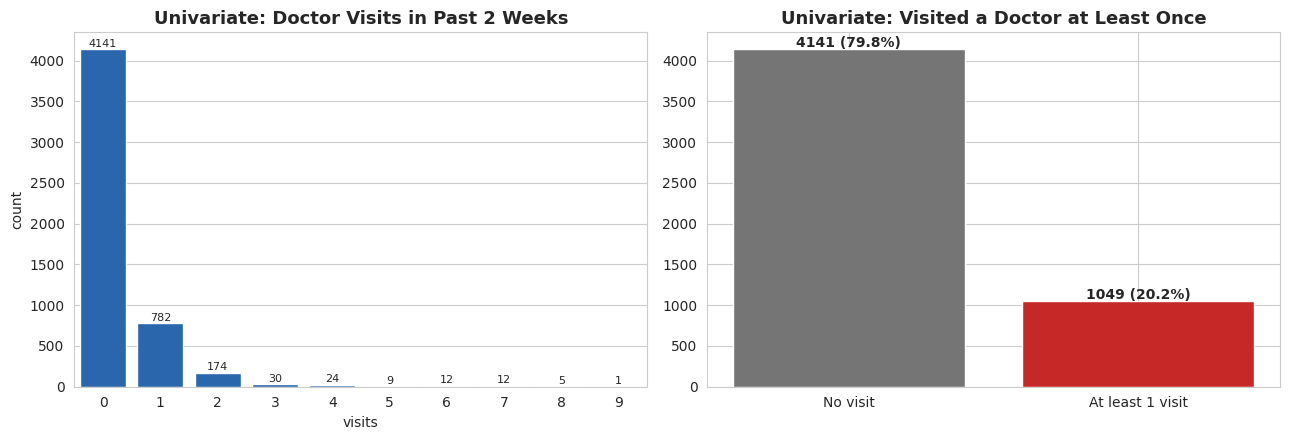

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=d, x='visits', ax=axes[0], color='#1565C0')
axes[0].set_title('Univariate: Doctor Visits in Past 2 Weeks', fontsize=13, fontweight='bold')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height() + 30), ha='center', fontsize=8)

vc = d['any_visit'].value_counts().sort_index()
bars = axes[1].bar(['No visit', 'At least 1 visit'], vc.values, color=['#757575', '#C62828'])
axes[1].set_title('Univariate: Visited a Doctor at Least Once', fontsize=13, fontweight='bold')
for b in bars:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 30, f'{int(b.get_height())} ({b.get_height()/len(d):.1%})', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

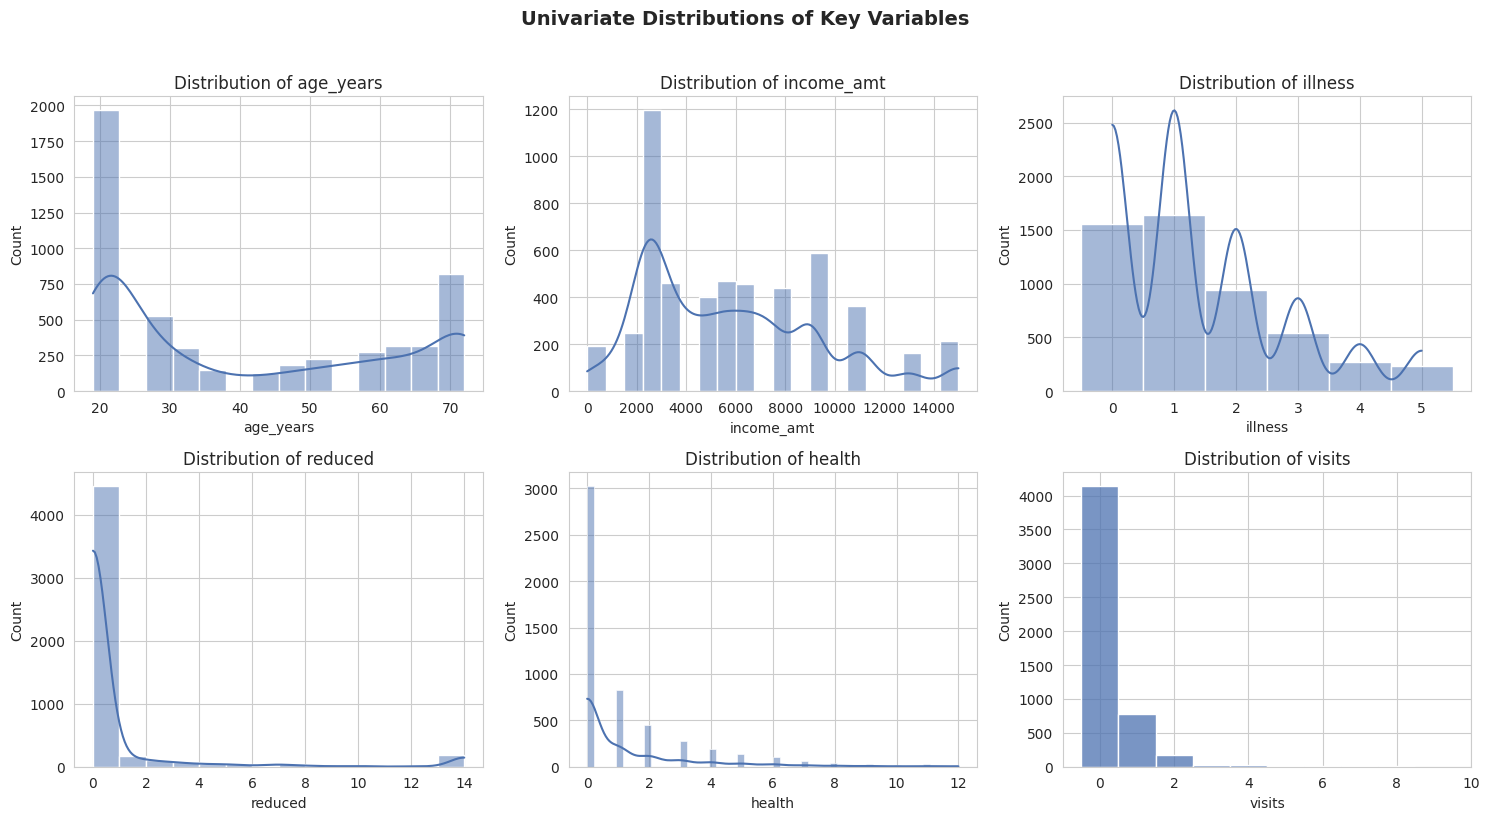

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
univariate_cols = ['age_years', 'income_amt', 'illness', 'reduced', 'health', 'visits']
for ax, c in zip(axes.flatten(), univariate_cols):
    sns.histplot(d[c], kde=(c not in ['visits']), ax=ax, color='#4C72B0', discrete=(c in ['illness', 'visits']))
    ax.set_title(f'Distribution of {c}')
fig.suptitle('Univariate Distributions of Key Variables', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

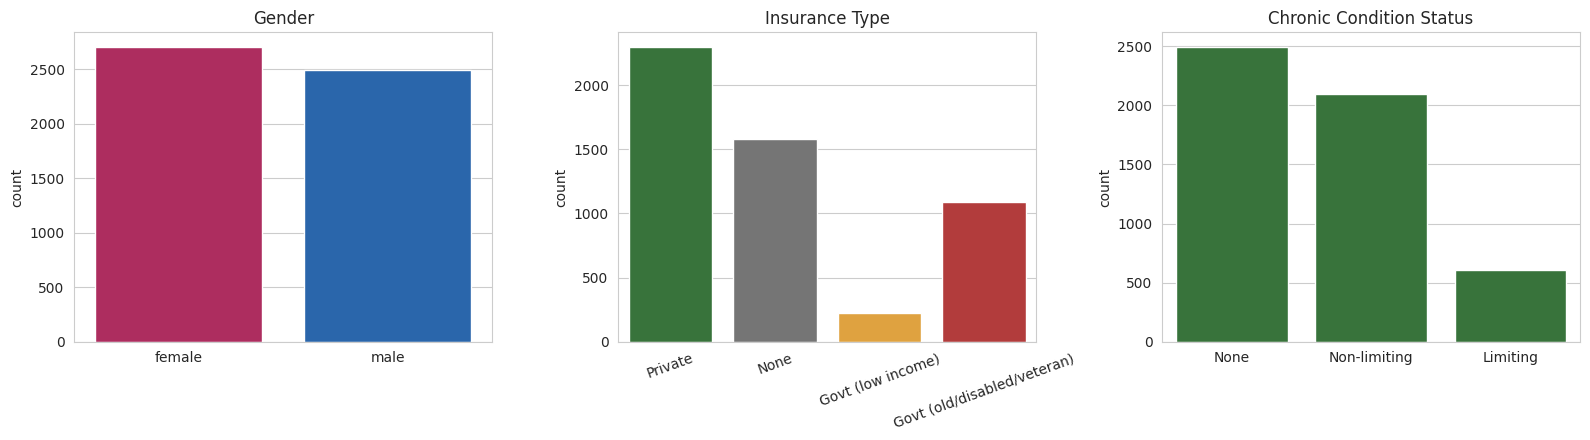

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.countplot(data=d, x='gender', ax=axes[0], palette=GENDER_PALETTE, hue='gender', legend=False)
axes[0].set_title('Gender')
sns.countplot(data=d, x='insurance', order=INS_ORDER, ax=axes[1], palette=INS_PALETTE, hue='insurance', legend=False)
axes[1].set_title('Insurance Type'); axes[1].tick_params(axis='x', rotation=20)
sns.countplot(data=d, x='chronic_status', order=['None', 'Non-limiting', 'Limiting'], ax=axes[2], color='#2E7D32')
axes[2].set_title('Chronic Condition Status')
for a in axes: a.set_xlabel('')
plt.tight_layout()
plt.show()

**Univariate findings:** About **80% of people (4,141 of 5,190) made no doctor visit** in the two weeks, and only a small tail made 3 or more visits. Age is bimodal, with one cluster of young adults (about 20-30) and another of older people (60+), income and reported illness are right-skewed toward low values, and most people report zero days of reduced activity. Private insurance is the most common cover, while government cover for low income is rare (~4%). About 40% of people have a non-limiting chronic condition and ~12% have a limiting one.

## 11. Bivariate Analysis

Examining the relationship between pairs of variables.

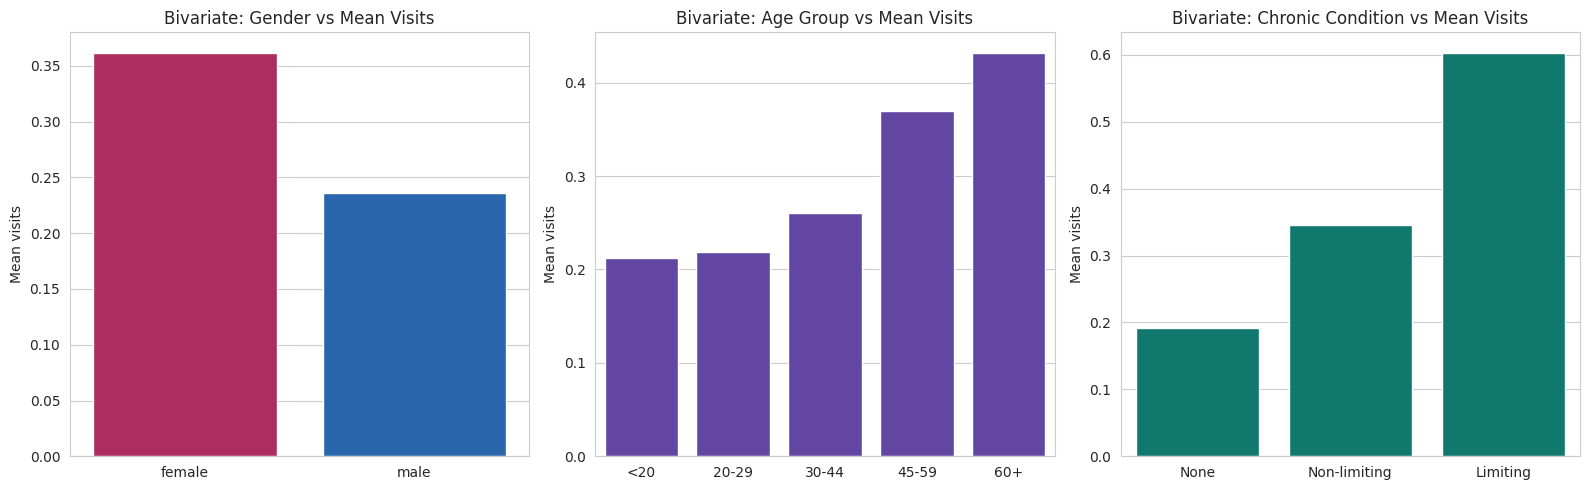

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(data=d, x='gender', y='visits', ax=axes[0], palette=GENDER_PALETTE, hue='gender', errorbar=None, legend=False)
axes[0].set_title('Bivariate: Gender vs Mean Visits')

sns.barplot(data=d, x='age_group', y='visits', order=AGE_ORDER, ax=axes[1], color='#5E35B1', errorbar=None)
axes[1].set_title('Bivariate: Age Group vs Mean Visits')

sns.barplot(data=d, x='chronic_status', y='visits', order=['None', 'Non-limiting', 'Limiting'], ax=axes[2], color='#00897B', errorbar=None)
axes[2].set_title('Bivariate: Chronic Condition vs Mean Visits')
for a in axes: a.set_ylabel('Mean visits'); a.set_xlabel('')
plt.tight_layout()
plt.show()

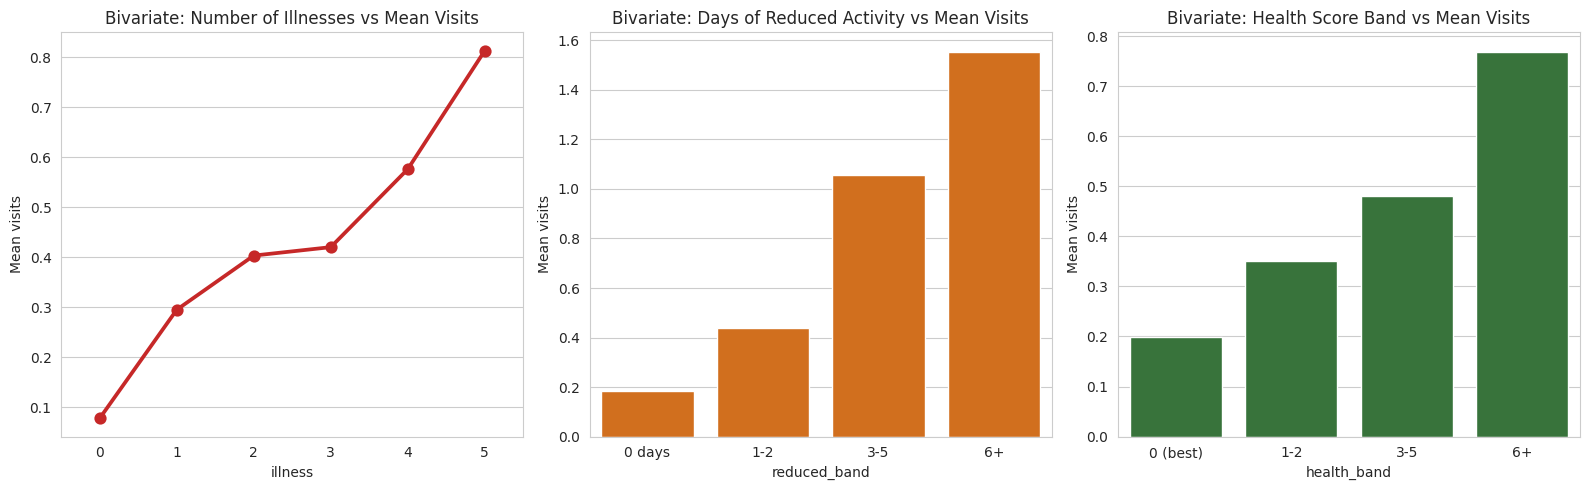

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.pointplot(data=d, x='illness', y='visits', ax=axes[0], color='#C62828', errorbar=None)
axes[0].set_title('Bivariate: Number of Illnesses vs Mean Visits')

sns.barplot(data=d, x='reduced_band', y='visits', ax=axes[1], color='#EF6C00', errorbar=None)
axes[1].set_title('Bivariate: Days of Reduced Activity vs Mean Visits')

sns.barplot(data=d, x='health_band', y='visits', ax=axes[2], color='#2E7D32', errorbar=None)
axes[2].set_title('Bivariate: Health Score Band vs Mean Visits')
for a in axes: a.set_ylabel('Mean visits')
plt.tight_layout()
plt.show()

In [23]:
d['income_quintile'] = pd.qcut(d['income_amt'], 5, duplicates='drop')
inc_visits = d.groupby('income_quintile', observed=True)['visits'].mean()
print("Mean visits by income quintile:")
print(inc_visits.round(3))

for c in ['illness', 'reduced', 'health', 'age_years', 'income_amt']:
    r, p = stats.spearmanr(d[c], d['visits'])
    print(f"Spearman correlation — {c:10s} vs visits: rho = {r:6.3f}, p = {p:.2e}")

Mean visits by income quintile:
income_quintile
(-0.001, 2500.0]     0.398
(2500.0, 3500.0]     0.359
(3500.0, 6500.0]     0.266
(6500.0, 9000.0]     0.223
(9000.0, 15000.0]    0.225
Name: visits, dtype: float64
Spearman correlation — illness    vs visits: rho =  0.263, p = 1.20e-82
Spearman correlation — reduced    vs visits: rho =  0.336, p = 8.45e-137
Spearman correlation — health     vs visits: rho =  0.178, p = 5.22e-38
Spearman correlation — age_years  vs visits: rho =  0.148, p = 1.18e-26
Spearman correlation — income_amt vs visits: rho = -0.093, p = 2.11e-11


**Bivariate findings:** Health indicators show the clearest, most graded relationships with visits. Mean visits climb from 0.08 for people with no illness to 0.81 for people with five illnesses, and from 0.18 for people with no reduced-activity days to 1.56 for those with six or more. Women visit more than men (0.36 vs 0.24), older age groups visit more (0.21 for under-20s up to 0.43 for 60+), and people with a limiting chronic condition visit far more (0.60) than those without one (0.26). Visits fall slightly with income (Spearman rho ≈ -0.09), while the strongest single association is with days of reduced activity (rho ≈ 0.34).

## 12. Multivariate Analysis

Examining three or more variables together to see how relationships interact.

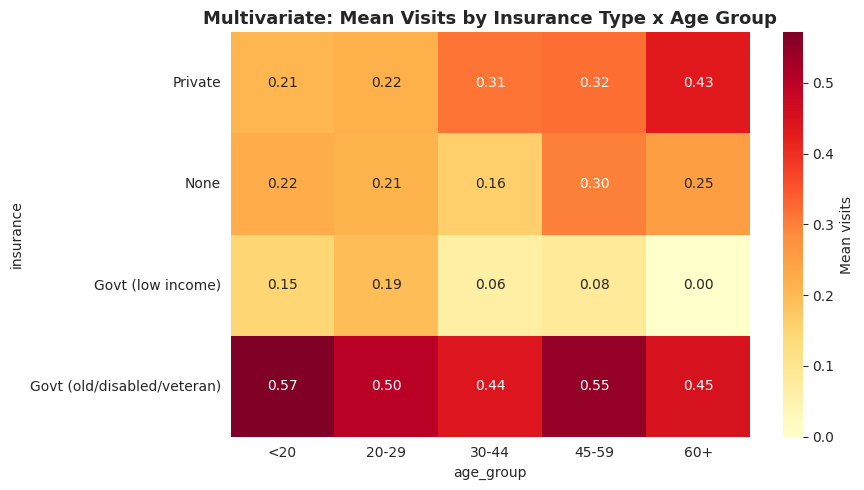

In [24]:
pivot_multi = d.pivot_table(index='insurance', columns='age_group', values='visits', aggfunc='mean', observed=True).loc[INS_ORDER, AGE_ORDER]

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pivot_multi, annot=True, fmt='.2f', cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Mean visits'})
ax.set_title('Multivariate: Mean Visits by Insurance Type x Age Group', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

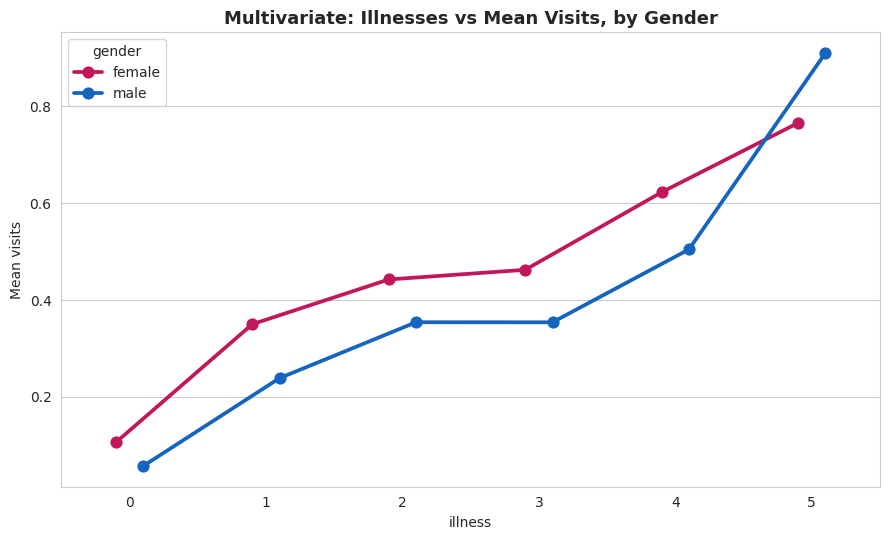

In [25]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.pointplot(data=d, x='illness', y='visits', hue='gender', palette=GENDER_PALETTE, errorbar=None, ax=ax, dodge=0.2)
ax.set_title('Multivariate: Illnesses vs Mean Visits, by Gender', fontsize=13, fontweight='bold')
ax.set_ylabel('Mean visits')
plt.tight_layout()
plt.show()

In [26]:
multi_summary = d.groupby(['insurance', 'chronic_status'], observed=True)[['visits', 'illness', 'reduced']].mean().round(2)
multi_summary

visits  illness  reduced
insurance                   chronic_status                          
Private                     Limiting          0.65     2.14     2.50
                            Non-limiting      0.32     1.73     0.77
                            None              0.20     0.87     0.39
None                        Limiting          0.34     2.14     1.86
                            Non-limiting      0.24     1.59     0.71
                            None              0.20     0.90     0.56
Govt (low income)           Limiting          0.23     2.00     2.50
                            Non-limiting      0.40     1.98     1.04
                            None              0.05     0.84     0.35
Govt (old/disabled/veteran) Limiting          0.72     2.49     3.01
                            Non-limiting      0.47     2.22     1.08
                            None              0.22     0.87     0.33

**Multivariate findings:** The insurance x age heatmap shows that the insurance groups have very different age profiles, which limits how far they can be compared: low-income government cover is mostly under 30 (only 4 people are 60+), while old-age/disability/veteran cover is overwhelmingly 60+ (only 7 people are under 20). Only privately insured people span all ages, and among them mean visits rise steadily with age (0.21 for under-20s to 0.43 for 60+). Women record more visits than men at every illness level except five illnesses (a small group), and both genders show the same steep rise as illness count increases, so illness count matters regardless of gender. The insurance x chronic-condition table also shows that people with government cover for old age / disability / veterans carry a much heavier illness and reduced-activity burden than the other groups, which is a first hint that their higher raw visit count reflects health need, not just their insurance type (tested formally in Section 15).

## 13. Correlation Analysis Completed

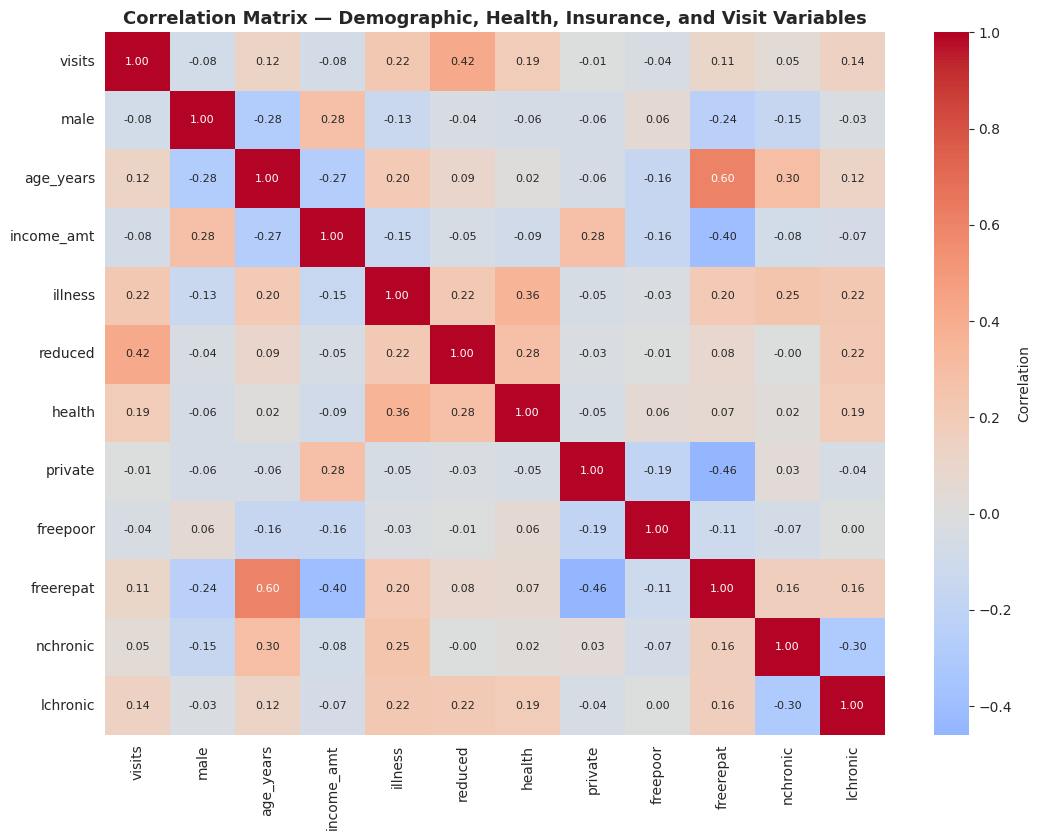

In [27]:
num_cols = ['visits', 'male', 'age_years', 'income_amt', 'illness', 'reduced', 'health',
            'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
corr = d[num_cols].corr()

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax,
            annot_kws={'size': 8}, cbar_kws={'label': 'Correlation'})
ax.set_title('Correlation Matrix — Demographic, Health, Insurance, and Visit Variables', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [28]:
print("Top correlates of visits:")
print(corr['visits'].drop('visits').sort_values(key=abs, ascending=False).head(6).round(3))

print("\nCorrelations among the health and demographic predictors:")
print(d[['age_years', 'income_amt', 'illness', 'reduced', 'health']].corr().round(3))

Top correlates of visits:
reduced      0.419
illness      0.224
health       0.193
lchronic     0.137
age_years    0.125
freerepat    0.107
Name: visits, dtype: float64

Correlations among the health and demographic predictors:
            age_years  income_amt  illness  reduced  health
age_years       1.000      -0.271    0.205    0.095   0.019
income_amt     -0.271       1.000   -0.149   -0.048  -0.086
illness         0.205      -0.149    1.000    0.218   0.360
reduced         0.095      -0.048    0.218    1.000   0.280
health          0.019      -0.086    0.360    0.280   1.000


**Correlation findings:**
- **Days of reduced activity is the strongest correlate of visits (r ≈ 0.42)**, followed by illness count (r ≈ 0.22) and health score (r ≈ 0.19).
- Demographics and insurance are much weaker. Age (r ≈ 0.13), limiting chronic condition (r ≈ 0.14), and government cover for old age/disability/veterans (r ≈ 0.11) show modest positive correlations, while being male (r ≈ -0.08) and higher income (r ≈ -0.08) show small negative ones.
- **Private insurance has essentially no correlation with visits (r ≈ -0.01)**.
- The predictors are also correlated with each other: older people report more illnesses (r ≈ 0.21) and have lower income (r ≈ -0.27), and illness is linked with health score (r ≈ 0.36). This overlap means some raw relationships partly reflect other variables, which Section 15 tests directly.

## 14. Group Comparisons Performed

### 14.1 Health Status Across Visit Levels

,illness,reduced,health,age_years
visit_group,,,,
0,1.26,0.43,1.02,39.03
1,2.02,1.80,1.77,47.10
2,2.46,3.31,2.40,46.41
3+,2.42,7.75,3.06,46.98


,lchronic,nchronic
visit_group,,
0,0.095,0.386
1,0.179,0.477
2,0.253,0.460
3+,0.301,0.452


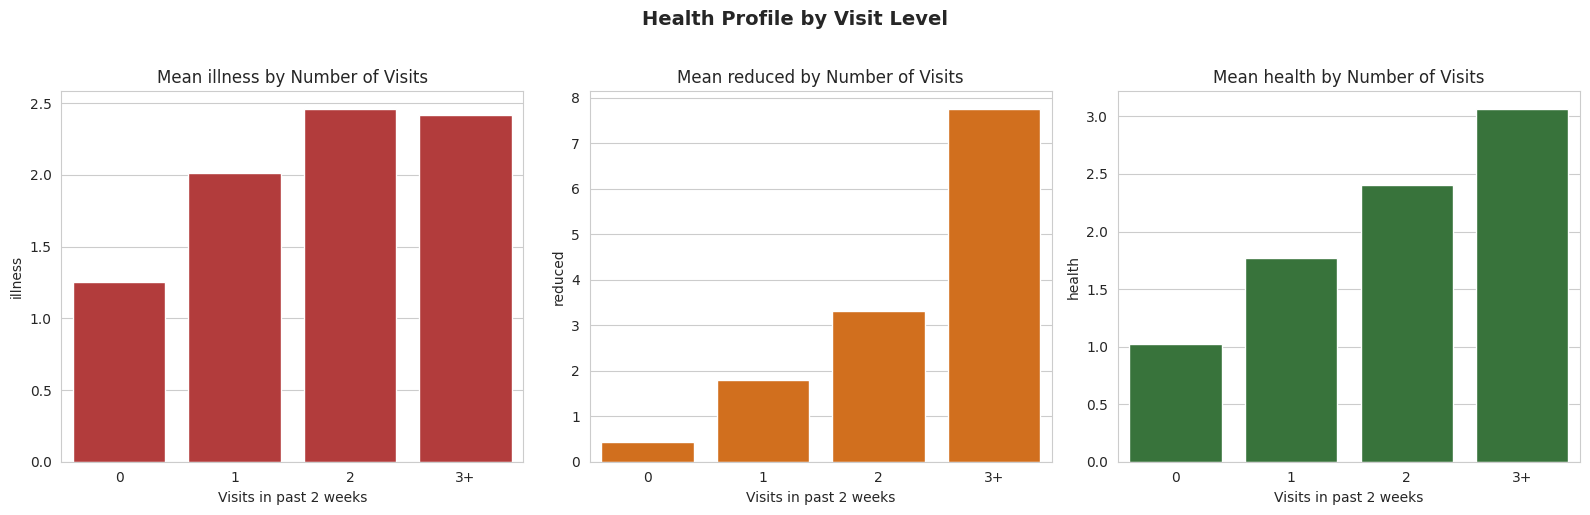

In [29]:
health_cols = ['illness', 'reduced', 'health', 'age_years']
display(d.groupby('visit_group', observed=True)[health_cols].mean().round(2))
display(d.groupby('visit_group', observed=True)[['lchronic', 'nchronic']].mean().round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, c, col in zip(axes, ['illness', 'reduced', 'health'], ['#C62828', '#EF6C00', '#2E7D32']):
    sns.barplot(data=d, x='visit_group', y=c, order=['0', '1', '2', '3+'], ax=ax, color=col, errorbar=None)
    ax.set_title(f'Mean {c} by Number of Visits'); ax.set_xlabel('Visits in past 2 weeks')
fig.suptitle('Health Profile by Visit Level', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Health findings:** Health burden rises steadily with the number of visits. People with no visits average 1.3 illnesses and about 0.4 days of reduced activity, while people with 3+ visits average 2.4 illnesses and 7.8 days of reduced activity. This confirms that visits mostly reflect medical need.

### 14.2 Insurance Coverage

,people,mean_visits,pct_any_visit,mean_age,mean_income,mean_illness,mean_reduced,mean_health
insurance,,,,,,,,
Private,2298,0.29,20.02,39.33,6980.37,1.36,0.77,1.10
None,1579,0.22,14.19,28.16,6544.46,1.19,0.69,1.12
Govt (low income),222,0.16,9.01,24.99,3013.96,1.26,0.77,1.80
Govt (old/disabled/veteran),1091,0.47,31.62,64.64,2953.53,1.97,1.33,1.50


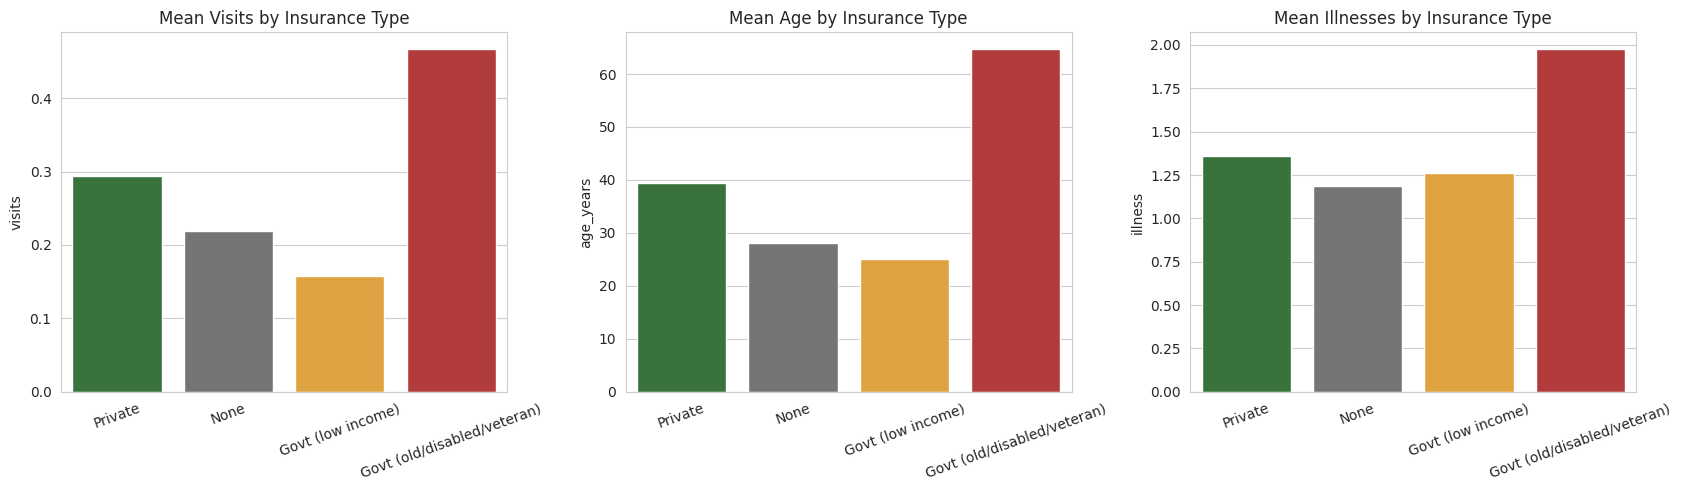

In [30]:
ins_table = d.groupby('insurance', observed=True).agg(people=('visits', 'size'), mean_visits=('visits', 'mean'),
                                                        pct_any_visit=('any_visit', 'mean'), mean_age=('age_years', 'mean'),
                                                        mean_income=('income_amt', 'mean'), mean_illness=('illness', 'mean'),
                                                        mean_reduced=('reduced', 'mean'), mean_health=('health', 'mean')).loc[INS_ORDER]
ins_table['pct_any_visit'] = ins_table['pct_any_visit'] * 100
display(ins_table.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.barplot(data=d, x='insurance', y='visits', order=INS_ORDER, palette=INS_PALETTE, hue='insurance', errorbar=None, ax=axes[0], legend=False)
axes[0].set_title('Mean Visits by Insurance Type')
sns.barplot(data=d, x='insurance', y='age_years', order=INS_ORDER, palette=INS_PALETTE, hue='insurance', errorbar=None, ax=axes[1], legend=False)
axes[1].set_title('Mean Age by Insurance Type')
sns.barplot(data=d, x='insurance', y='illness', order=INS_ORDER, palette=INS_PALETTE, hue='insurance', errorbar=None, ax=axes[2], legend=False)
axes[2].set_title('Mean Illnesses by Insurance Type')
for a in axes: a.set_xlabel(''); a.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

In [31]:
groups_ins = [d[d['insurance'] == g]['visits'] for g in INS_ORDER]
f_i, p_i = stats.f_oneway(*groups_ins)
print(f"One-way ANOVA (visits across insurance types): F = {f_i:.3f}, p = {p_i:.2e}")
h_i, p_k = stats.kruskal(*groups_ins)
print(f"Kruskal-Wallis (non-parametric check):        H = {h_i:.3f}, p = {p_k:.2e}")
chi, p_c, _, _ = stats.chi2_contingency(pd.crosstab(d['insurance'], d['any_visit']))
print(f"Chi-square (any visit vs insurance):          chi2 = {chi:.1f}, p = {p_c:.2e}")

One-way ANOVA (visits across insurance types): F = 24.020, p = 1.97e-15
Kruskal-Wallis (non-parametric check):        H = 138.063, p = 9.89e-30
Chi-square (any visit vs insurance):          chi2 = 141.0, p = 2.34e-30


**Insurance findings:** Visits differ significantly by insurance type (ANOVA p < 0.001). People with government cover for old age / disability / veterans visit most (0.47 mean visits, 32% saw a doctor), while those with low-income government cover visit least (0.16, 9%). Private insurance sits in between (0.29). The old/disabled/veteran group is also much older (average age 65) and sicker (2.0 illnesses vs about 1.2-1.4 elsewhere), so this comparison mixes insurance with health need, which Section 15 separates.

### 14.3 Demographics: Gender, Age and Income

,visits,any_visit,age_years,income_amt,illness,reduced,health
gender,,,,,,,
female,0.362,0.244,46.162,4852.517,1.611,0.976,1.335
male,0.236,0.156,34.639,6894.895,1.238,0.738,1.090


Mann-Whitney U (visits, male vs female): p = 6.34e-15
Kruskal-Wallis (visits across age groups): H = 113.6, p = 1.21e-23


,visits,income_amt
age_group,,
<20,0.21,4183.38
20-29,0.22,7100.17
30-44,0.26,9014.49
45-59,0.37,6315.24
60+,0.43,3688.78


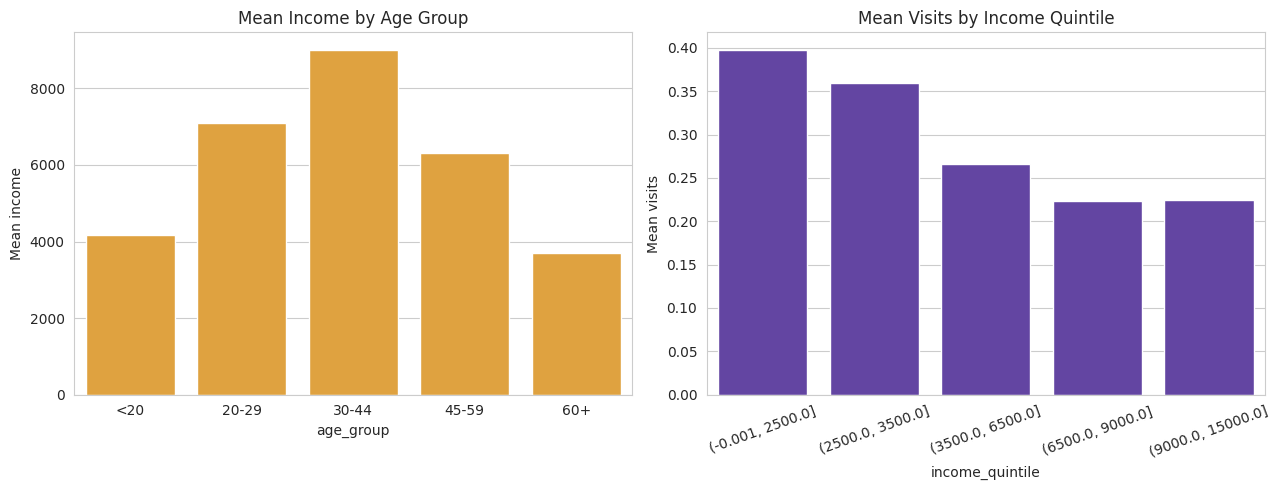

In [32]:
demo_gender = d.groupby('gender')[['visits', 'any_visit', 'age_years', 'income_amt', 'illness', 'reduced', 'health']].mean().round(3)
display(demo_gender)

u, p_u = stats.mannwhitneyu(d[d.male == 1]['visits'], d[d.male == 0]['visits'])
print(f"Mann-Whitney U (visits, male vs female): p = {p_u:.2e}")

groups_age = [d[d['age_group'] == g]['visits'] for g in AGE_ORDER]
h_a, p_a = stats.kruskal(*groups_age)
print(f"Kruskal-Wallis (visits across age groups): H = {h_a:.1f}, p = {p_a:.2e}")

display(d.groupby('age_group', observed=True)[['visits', 'income_amt']].mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=d, x='age_group', y='income_amt', order=AGE_ORDER, ax=axes[0], color='#F9A825', errorbar=None)
axes[0].set_title('Mean Income by Age Group'); axes[0].set_ylabel('Mean income')
sns.barplot(data=d, x='income_quintile', y='visits', ax=axes[1], color='#5E35B1', errorbar=None)
axes[1].set_title('Mean Visits by Income Quintile'); axes[1].set_ylabel('Mean visits'); axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

**Demographic findings:** Women have 50% more visits than men (0.36 vs 0.24, p < 0.001) and are also older (46 vs 35 years on average) and sicker (1.6 vs 1.2 illnesses), so part of the gap is again a health-and-age effect. Visits rise steadily with age (0.21 for under-20s up to 0.43 for 60+, Kruskal-Wallis p < 0.001). Income peaks in the 30-44 age band (about 9,000) and is lowest for 60+ (about 3,700), so income and age are entangled, and the small negative raw relationship between income and visits should be read with that in mind.

## 15. Student-Designed Analysis 1 — The Hidden Effect Behind Insurance and Chronic Conditions


In [33]:
covars = 'male + age_years + income + illness + reduced + health + private + freepoor + freerepat + nchronic + lchronic'
rows = []
for v in ['private', 'freepoor', 'freerepat', 'nchronic', 'lchronic', 'male']:
    raw = smf.negativebinomial(f'visits ~ {v}', data=d).fit(disp=False, maxiter=200)
    rows.append({'Variable': v, 'Model': 'Raw (unadjusted)', 'IRR': np.exp(raw.params[v]), 'p': raw.pvalues[v]})
adj = smf.negativebinomial(f'visits ~ {covars}', data=d).fit(disp=False, maxiter=200)
for v in ['private', 'freepoor', 'freerepat', 'nchronic', 'lchronic', 'male']:
    rows.append({'Variable': v, 'Model': 'Adjusted (all controls)', 'IRR': np.exp(adj.params[v]), 'p': adj.pvalues[v]})
cmp = pd.DataFrame(rows)
display(cmp.pivot(index='Variable', columns='Model', values=['IRR', 'p']).round(3))

IRR                                        p                 
Model     Adjusted (all controls) Raw (unadjusted) Adjusted (all controls) Raw (unadjusted)
Variable                                                                                   
freepoor                    0.609            0.512                   0.016            0.001
freerepat                   1.157            1.809                   0.211            0.000
lchronic                    1.201            2.303                   0.075            0.000
male                        0.806            0.653                   0.002            0.000
nchronic                    1.103            1.270                   0.212            0.000
private                     1.124            0.958                   0.171            0.534

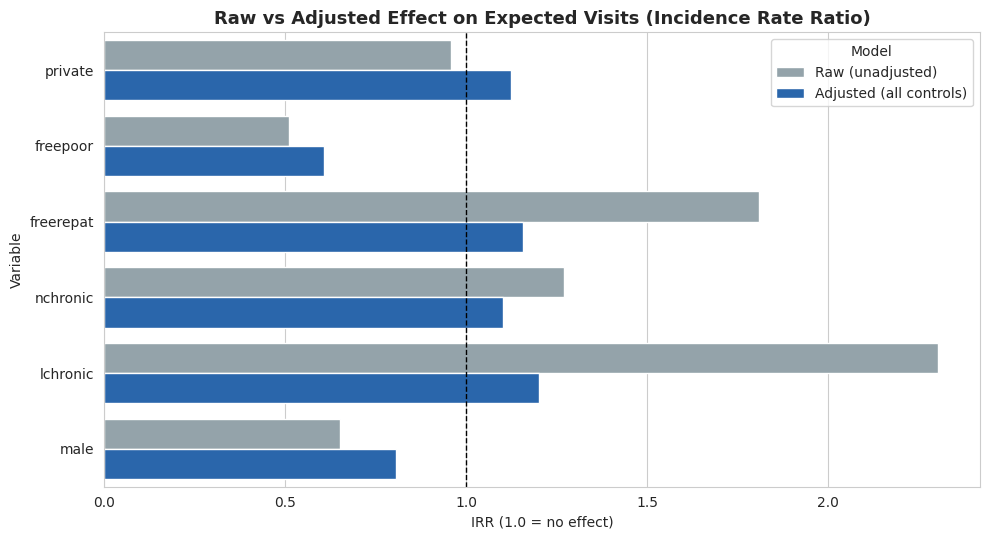

In [34]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=cmp, y='Variable', x='IRR', hue='Model', palette=['#90A4AE', '#1565C0'], ax=ax)
ax.axvline(1, color='black', linewidth=1, linestyle='--')
ax.set_title('Raw vs Adjusted Effect on Expected Visits (Incidence Rate Ratio)', fontsize=13, fontweight='bold')
ax.set_xlabel('IRR (1.0 = no effect)')
plt.tight_layout()
plt.show()

In [35]:
# Who is in the government old-age / disability / veteran group?
d.groupby('freerepat')[['age_years', 'illness', 'reduced', 'health', 'lchronic', 'visits']].mean().round(3)

,age_years,illness,reduced,health,lchronic,visits
freerepat,,,,,,
0,34.249,1.288,0.737,1.143,0.090,0.258
1,64.643,1.974,1.331,1.499,0.217,0.467


**Finding.** On their own, several factors look like strong drivers of visits: government old-age/disability/veteran cover (raw IRR ≈ 1.8, i.e. +81%), limiting chronic condition (≈ 2.3, +130%), non-limiting chronic condition (≈ 1.3) and being male (≈ 0.65). But **once illness, days of reduced activity, health score, age and income are controlled for, the effects of old-age/disability/veteran cover, both chronic condition flags and private insurance are no longer statistically significant** (adjusted IRRs ≈ 1.16, 1.20, 1.10 and 1.12 respectively, all p > 0.05). The reason is visible in the last table: the government old-age/disability/veteran group is 65 years old on average, with 2.0 illnesses and 1.3 reduced-activity days, versus 34 years, 1.3 illnesses and 0.7 days for everyone else. Their higher visit count is **explained by their health need**, not by their insurance. Two effects survive the controls: **men visit about 20% less than women** (IRR ≈ 0.81) and **people on low-income government cover visit about 39% less** (IRR ≈ 0.61) than would be expected for their health. That last result is the one that points to a genuine access or utilisation gap.

## 16. Student-Designed Analysis 2 — Count Model Deep-Dive (Poisson vs Negative Binomial)



In [36]:
formula = 'visits ~ male + age_years + income + illness + reduced + health + private + freepoor + freerepat + nchronic + lchronic'
poisson = smf.glm(formula, data=d, family=sm.families.Poisson()).fit()
nb = smf.negativebinomial(formula, data=d).fit(disp=False, maxiter=200)

dispersion = poisson.pearson_chi2 / poisson.df_resid
print(f"Poisson Pearson dispersion = {dispersion:.2f}  (1.0 = no overdispersion)")
print(f"AIC  Poisson: {poisson.aic:.1f}  |  Negative Binomial: {nb.aic:.1f}  (lower = better)")
print(f"NegBin overdispersion parameter alpha = {nb.params['alpha']:.3f}")

# Zero check: does each model reproduce the ~80% zeros?
alpha = nb.params['alpha']
mu_nb = nb.predict(d)
print(f"\nObserved share of zeros: {(d['visits']==0).mean():.3f}")
print(f"Poisson predicted zeros: {np.exp(-poisson.predict(d)).mean():.3f}")
print(f"NegBin predicted zeros:  {((1 + alpha*mu_nb) ** (-1/alpha)).mean():.3f}")

Poisson Pearson dispersion = 1.33  (1.0 = no overdispersion)
AIC  Poisson: 6735.7  |  Negative Binomial: 6423.7  (lower = better)
NegBin overdispersion parameter alpha = 1.075

Observed share of zeros: 0.798
Poisson predicted zeros: 0.773
NegBin predicted zeros:  0.804


,IRR,CI_low,CI_high,p_value,Significant
illness,1.240,1.182,1.300,0.000,True
lchronic,1.201,0.981,1.471,0.075,False
freerepat,1.157,0.920,1.455,0.211,False
reduced,1.155,1.137,1.172,0.000,True
private,1.124,0.951,1.329,0.171,False
nchronic,1.103,0.945,1.287,0.212,False
health,1.038,1.011,1.067,0.006,True
age_years,1.003,0.999,1.007,0.113,False
income,0.855,0.699,1.047,0.129,False
male,0.806,0.703,0.923,0.002,True


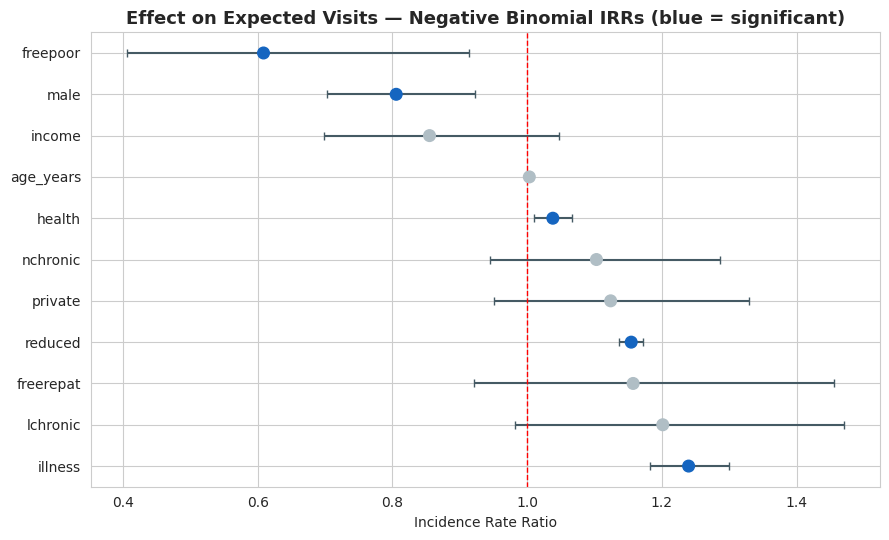

In [37]:
coefs = nb.params.drop(['Intercept', 'alpha'])
ci = nb.conf_int().drop(['Intercept', 'alpha'])
irr = pd.DataFrame({'IRR': np.exp(coefs), 'CI_low': np.exp(ci[0]), 'CI_high': np.exp(ci[1]),
                    'p_value': nb.pvalues.drop(['Intercept', 'alpha'])}).sort_values('IRR', ascending=False)
irr['Significant'] = irr['p_value'] < 0.05
display(irr.round(3))

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ['#1565C0' if s else '#B0BEC5' for s in irr['Significant']]
ax.errorbar(irr['IRR'], range(len(irr)), xerr=[irr['IRR'] - irr['CI_low'], irr['CI_high'] - irr['IRR']],
            fmt='none', ecolor='#455A64', capsize=3)
ax.scatter(irr['IRR'], range(len(irr)), c=colors, s=70, zorder=3)
ax.axvline(1, color='red', linewidth=1, linestyle='--')
ax.set_yticks(range(len(irr))); ax.set_yticklabels(irr.index)
ax.set_title('Effect on Expected Visits — Negative Binomial IRRs (blue = significant)', fontsize=13, fontweight='bold')
ax.set_xlabel('Incidence Rate Ratio')
plt.tight_layout()
plt.show()

**Finding.** A Poisson model assumes variance equals the mean, but here the Poisson dispersion is about **1.33** and the variance of visits is about twice the mean, so the data are overdispersed. The **Negative Binomial model fits substantially better** (AIC ≈ 6,424 vs ≈ 6,736 for Poisson) and reproduces the observed share of zeros almost exactly (80.4% predicted vs 79.8% observed, whereas Poisson predicts only 77.3%), so a more complex zero-inflated model is not clearly needed. In this model, **each additional illness raises expected visits by about 24%, each additional day of reduced activity by about 16%, and each additional point on the health score by about 4%**. The strongest significant protective effects are being male (about 20% fewer visits) and low-income government cover (about 39% fewer). Age, income, private insurance and the chronic-condition flags do not add significant explanatory power once health need is included.

## 17. Student-Designed Analysis 3 — Gender x Age Consistency Check



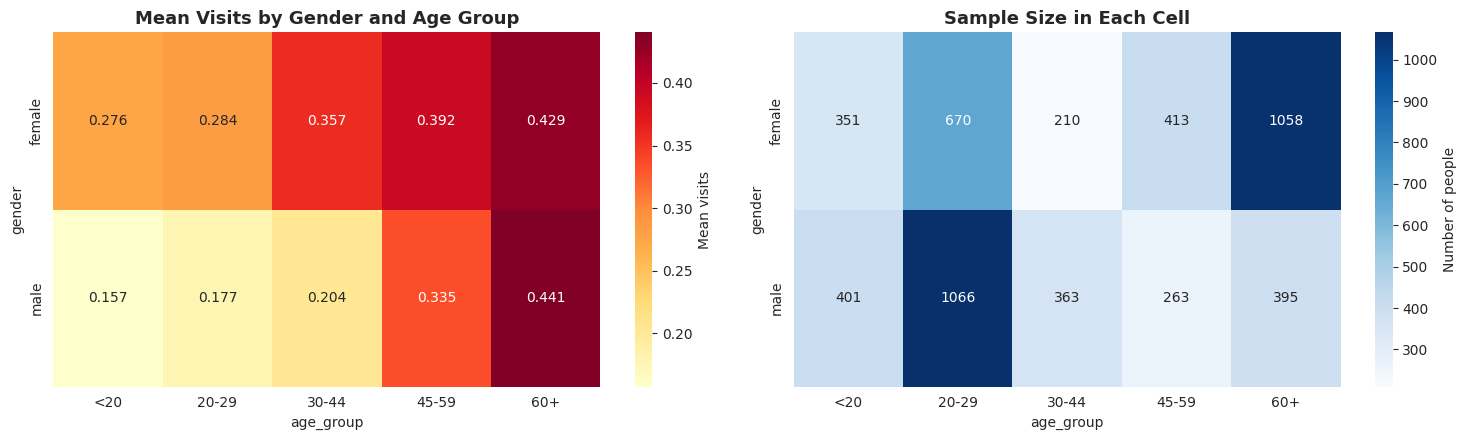

In [38]:
gender_age = d.pivot_table(index='gender', columns='age_group', values='visits', aggfunc='mean', observed=True)[AGE_ORDER]
counts = d.pivot_table(index='gender', columns='age_group', values='visits', aggfunc='size', observed=True)[AGE_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(gender_age, annot=True, fmt='.3f', cmap='YlOrRd', ax=axes[0], cbar_kws={'label': 'Mean visits'})
axes[0].set_title('Mean Visits by Gender and Age Group', fontsize=13, fontweight='bold')
sns.heatmap(counts, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar_kws={'label': 'Number of people'})
axes[1].set_title('Sample Size in Each Cell', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [39]:
gap = gender_age.loc['female'] - gender_age.loc['male']
print("Female minus male mean visits, by age group:")
print(gap.round(3))
print(f"\nAge groups where women visit more than men: {(gap > 0).sum()} out of {len(gap)}")

Female minus male mean visits, by age group:
age_group
<20      0.119
20-29    0.106
30-44    0.153
45-59    0.058
60+     -0.011
dtype: float64

Age groups where women visit more than men: 4 out of 5


## 18. Final Conclusion

This analysis shows that doctor visits in this survey are driven mainly by **medical need**, and that several apparent demographic and insurance effects are largely a reflection of who is sick. Visits are rare (about 80% of people had none), heavily skewed, and rise steadily and consistently with illness count, days of reduced activity and poorer general health. Older people, women, and people with government old-age/disability/veteran cover appear to visit far more in raw comparisons, but the adjusted Negative Binomial analysis shows that most of this is explained by their worse health.

Two effects remain after controlling for health: **men visit about 20% less than women** (with the gap concentrated below age 60), and **people on low-income government cover visit about 39% less** than their health would predict. These are the clearest signs of a possible engagement or access gap, and the most useful starting points for follow-up. The main methodological lesson mirrors good practice in any observational data: always compare groups after accounting for the factors that differ between them, and use models that match the shape of the outcome. For a zero-heavy count like doctor visits, that means a Negative Binomial model rather than raw averages or linear regression.